In [11]:
import sys
sys.path.insert(0, "../..")

import numpy as np
import matplotlib.pyplot as plt

from unc_pma.environments import NoisyGridworld
from unc_pma.bayesian_qlearning import BayesianQLearning, NormalGamma
from unc_pma.environment_model import DirichletTransitionsModel
from unc_pma.replay_sampling_agent import ReplaySamplerAgent, plot_state_grid

np.random.seed(42)
plt.rcParams.update({"figure.dpi": 120, "font.size": 11})

Config : 'hard' -- 5x5, walls, slip=0.0, noise=0.3
states=25  actions=4  N_STEPS=50000  N_INIT_STEPS=400  WINDOW=200


<Axes: >

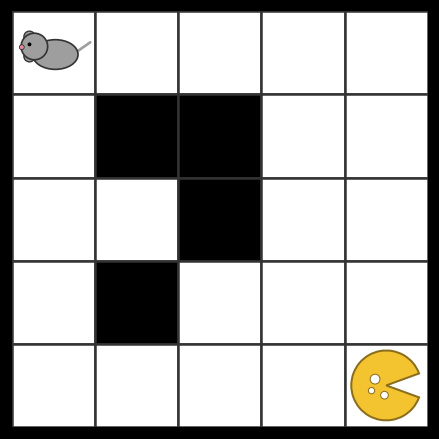

In [12]:
# Set WORLD = "easy"  ->  4x4, no walls, low noise
#     WORLD = "hard"  ->  5x5, walls,    higher noise
WORLD = "hard"

CONFIGS = {
    "easy": dict(
        height=4, width=4,
        start=(0, 0),
        goals={(3, 3): 1.0},
        walls=set(),
        slip_prob=0.0,#0.1,
        reward_noise=0.1,
        step_cost=0.0,
        gamma=0.99,
        n_steps=50_000,
        n_init_steps=4000,
        window=100,
        description="4x4, no walls, slip=0.0, noise=0.1",
    ),
    "hard": dict(
        height=5, width=5,
        start=(0, 0),
        goals={(4, 4): 1.0},
        walls={(1, 1), (1, 2), (2, 2), (3, 1)},
        slip_prob=0.1,#0.2,
        reward_noise=0.3,
        step_cost=0.0,
        gamma=0.99,
        n_steps=50000,
        n_init_steps=400,
        window=200,
        description="5x5, walls, slip=0.0, noise=0.3",
    ),
}

cfg          = CONFIGS[WORLD]
GAMMA        = cfg["gamma"]
N_STEPS      = cfg["n_steps"]
N_INIT_STEPS = cfg["n_init_steps"]
WINDOW       = cfg["window"]

env = NoisyGridworld(
    height      = cfg["height"],
    width       = cfg["width"],
    start       = cfg["start"],
    goals       = cfg["goals"],
    walls       = cfg["walls"],
    slip_prob   = cfg["slip_prob"],
    reward_noise= cfg["reward_noise"],
    step_cost   = cfg["step_cost"],
)
print(f"Config : {WORLD!r} -- {cfg['description']}")
print(f"states={env.n_states}  actions={env.n_actions}  "
      f"N_STEPS={N_STEPS}  N_INIT_STEPS={N_INIT_STEPS}  WINDOW={WINDOW}")
env.maze_render()

In [13]:
# --- Transition model (Dirichlet), seeded to ground truth -------------------
# The agent isn't learning the maze dynamics here: T(s'|s,a) is set directly
# to the environment's real deterministic transition. Each (s,a) gets an
# *exact* one-hot posterior rather than a merely concentrated one -- a
# Dirichlet built from .update() calls would leave every other destination a
# tiny residual probability, occasionally sampling a "jump" over unvisited
# cells in a long replay trajectory.
transition_model = DirichletTransitionsModel(env.n_states, env.n_actions)
for r in range(env.height):
    for c in range(env.width):
        if (r, c) in env.walls:
            continue
        s = env._encode(r, c)
        for a in range(env.n_actions):
            next_state, _, _ = env.deterministic_transition(s, a)
            transition_model.alpha[s, a, :] = 0.0
            transition_model.alpha[s, a, next_state] = 1.0

# Wall rows are skipped above, so they would keep the class's flat
# alpha_prior -- effectively "a wall leads anywhere". That matters because
# expected_prev_state_evb scans every (s',a') as a candidate predecessor,
# walls included, so their leftover mass would drag the INVALID_EVB sentinel
# into real states' BEVB. mark_dead_end pins them to a self-loop instead, so
# they contribute exactly zero.
wall_states = [env._encode(r, c) for (r, c) in env.walls]
transition_model.mark_dead_end(wall_states)

# --- Self-loop (state, action) exclusion ------------------------------------
# An action that bumps into a wall OR walks off the grid edge is reflected
# back by deterministic_transition, so both are self-loops with T(s|s,a)=1.
# Forward search can never move from such a pair -- its only successor is
# already in visited_states -- so the tree gets flushed before "forward" is
# recorded, and a real forward decision is mislabelled "root only". Backward
# ignores the action entirely and is unaffected, which is what skewed the
# strategy frequencies. Keying the mask on the actual self-loop covers wall
# bumps and boundary bumps alike.
#
# This is a modelling choice, not just bookkeeping: these pairs are no longer
# replayed at all, so their Q-values can only be updated from real steps.
valid_state_actions = np.ones((env.n_states, env.n_actions), dtype=bool)
for r in range(env.height):
    for c in range(env.width):
        if (r, c) in env.walls:
            continue
        s = env._encode(r, c)
        for a in range(env.n_actions):
            if env.deterministic_transition(s, a)[0] == s:  # wall or boundary bump
                valid_state_actions[s, a] = False

# --- Reward model (Bayesian Q-learning prior) -------------------------------
# Every real state gets the same flat mu -- step_cost is 0 and the goal's
# one-step reward is ignored -- so the seeded q_model carries no information
# about where the reward is; only replay/experience can move it toward the
# true, non-flat Q-values. lam/alpha match what .update() would produce after
# N_SEED_OBS observations, so it is confident about that uninformative mean.
#
# Wall states are left at the class's default prior. Their Q-values are
# structurally unreachable -- valid_states masks them out of root selection,
# and T(wall | real state, a) = 0 weights them by a hard zero everywhere else
# -- so whatever they hold never matters.
N_SEED_OBS = 5  # "pretend we've already observed this reward N times"
LAM_SEED = 1.0 + N_SEED_OBS
ALPHA_SEED = 1.0 + N_SEED_OBS * 0.5
MIN_REWARD_STD = 1e-6  # numerical floor so NormalGamma.scale never hits exactly 0
FLAT_REWARD_MU = 0.0   # same mu for every real state -- no reward-location signal

q_model = BayesianQLearning(env.n_states, env.n_actions, gamma=GAMMA)
for r in range(env.height):
    for c in range(env.width):
        if (r, c) in env.walls:
            continue
        s = env._encode(r, c)
        for a in range(env.n_actions):
            _, _, done = env.deterministic_transition(s, a)
            reward_std = env.reward_noise if (not env.reward_noise_at_goal_only or done) else 0.0
            reward_std = max(reward_std, MIN_REWARD_STD)
            q_model._q[s][a] = NormalGamma(
                mu=FLAT_REWARD_MU, lam=LAM_SEED, alpha=ALPHA_SEED, beta=ALPHA_SEED * reward_std ** 2,
            )

# --- Replay sampler ---------------------------------------------------------
valid_states = np.ones(env.n_states, dtype=bool)
valid_states[wall_states] = False

start_state = env._encode(*env.start)
replay_agent = ReplaySamplerAgent(
    q_model, transition_model,
    need_from_position=True,
    H=500,
    agent_real_state=start_state,
    SR_policy="thomson_sampling",
    valid_states=valid_states,
    valid_state_actions=valid_state_actions,
)

print(f"transition_model: n_states={transition_model.n_states} n_actions={transition_model.n_actions}")
print(f"q_model: n_states={q_model.n_states} n_actions={q_model.n_actions} gamma={q_model.gamma}")
print(f"replay_agent.agent_real_state={replay_agent.agent_real_state} (start={env.start})")
print(f"P(wall as destination) from valid sources, max: {transition_model.alpha[valid_states][:, :, wall_states].max()} (should be 0.0)")
print(f"self-loop (state, action) pairs excluded: {(~valid_state_actions).sum()}")

transition_model: n_states=25 n_actions=4
q_model: n_states=25 n_actions=4 gamma=0.99
replay_agent.agent_real_state=0 (start=(0, 0))
P(wall as destination) from valid sources, max: 0.0 (should be 0.0)
self-loop (state, action) pairs excluded: 32


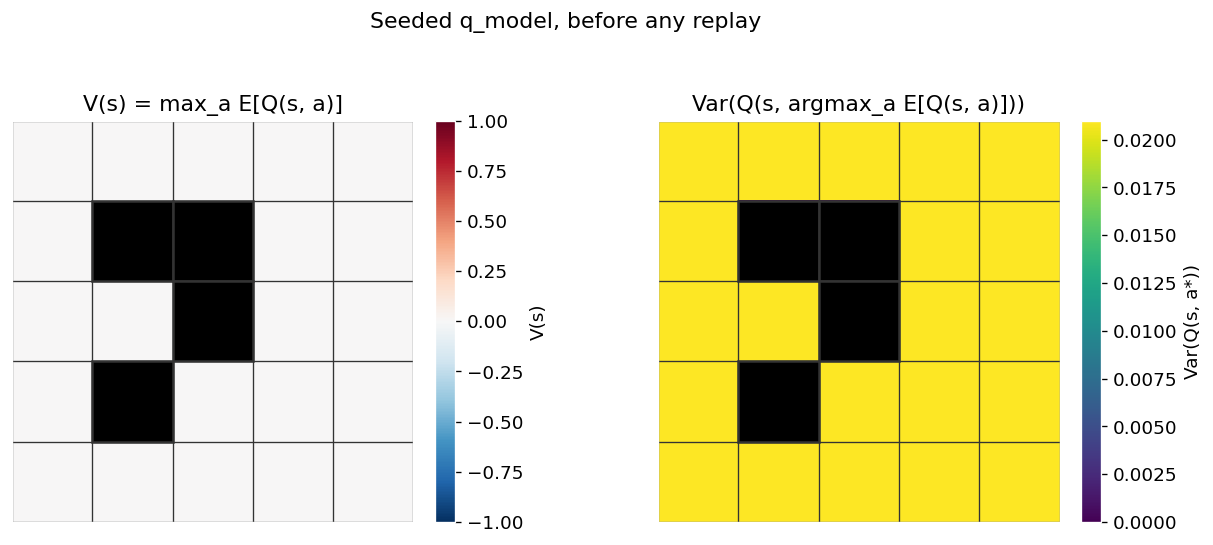

In [14]:
# --- Initial V(s) and Var(s) from the seeded q_model ------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), facecolor="white")
replay_agent.plot_value_function(env.height, env.width, walls=env.walls, ax=axes[0])
replay_agent.plot_value_variance(env.height, env.width, walls=env.walls, ax=axes[1])
fig.suptitle("Seeded q_model, before any replay", color="black")
for ax in axes:
    ax.title.set_color("black")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

Sampled 154 replay trajectories, lengths: [4, 3, 4, 2, 2, 2, 1, 8, 2, 2, 6, 1, 2, 1, 1, 2, 1, 2, 2, 2, 1, 1, 2, 4, 1, 1, 2, 5, 2, 6, 1, 2, 2, 3, 5, 3, 1, 2, 1, 1, 2, 8, 2, 2, 1, 2, 3, 1, 4, 2, 1, 2, 2, 3, 3, 1, 1, 1, 3, 4, 3, 8, 1, 1, 1, 1, 2, 1, 1, 1, 4, 2, 2, 1, 1, 3, 3, 1, 2, 2, 1, 2, 1, 6, 1, 1, 1, 3, 4, 2, 1, 3, 2, 1, 2, 3, 1, 1, 2, 2, 4, 2, 2, 3, 4, 1, 1, 5, 2, 2, 1, 2, 2, 4, 2, 1, 2, 3, 2, 5, 5, 3, 3, 2, 1, 1, 3, 1, 2, 2, 2, 3, 2, 1, 2, 1, 1, 1, 2, 1, 1, 1, 2, 1, 2, 3, 2, 1, 4, 2, 6, 1, 5, 2]


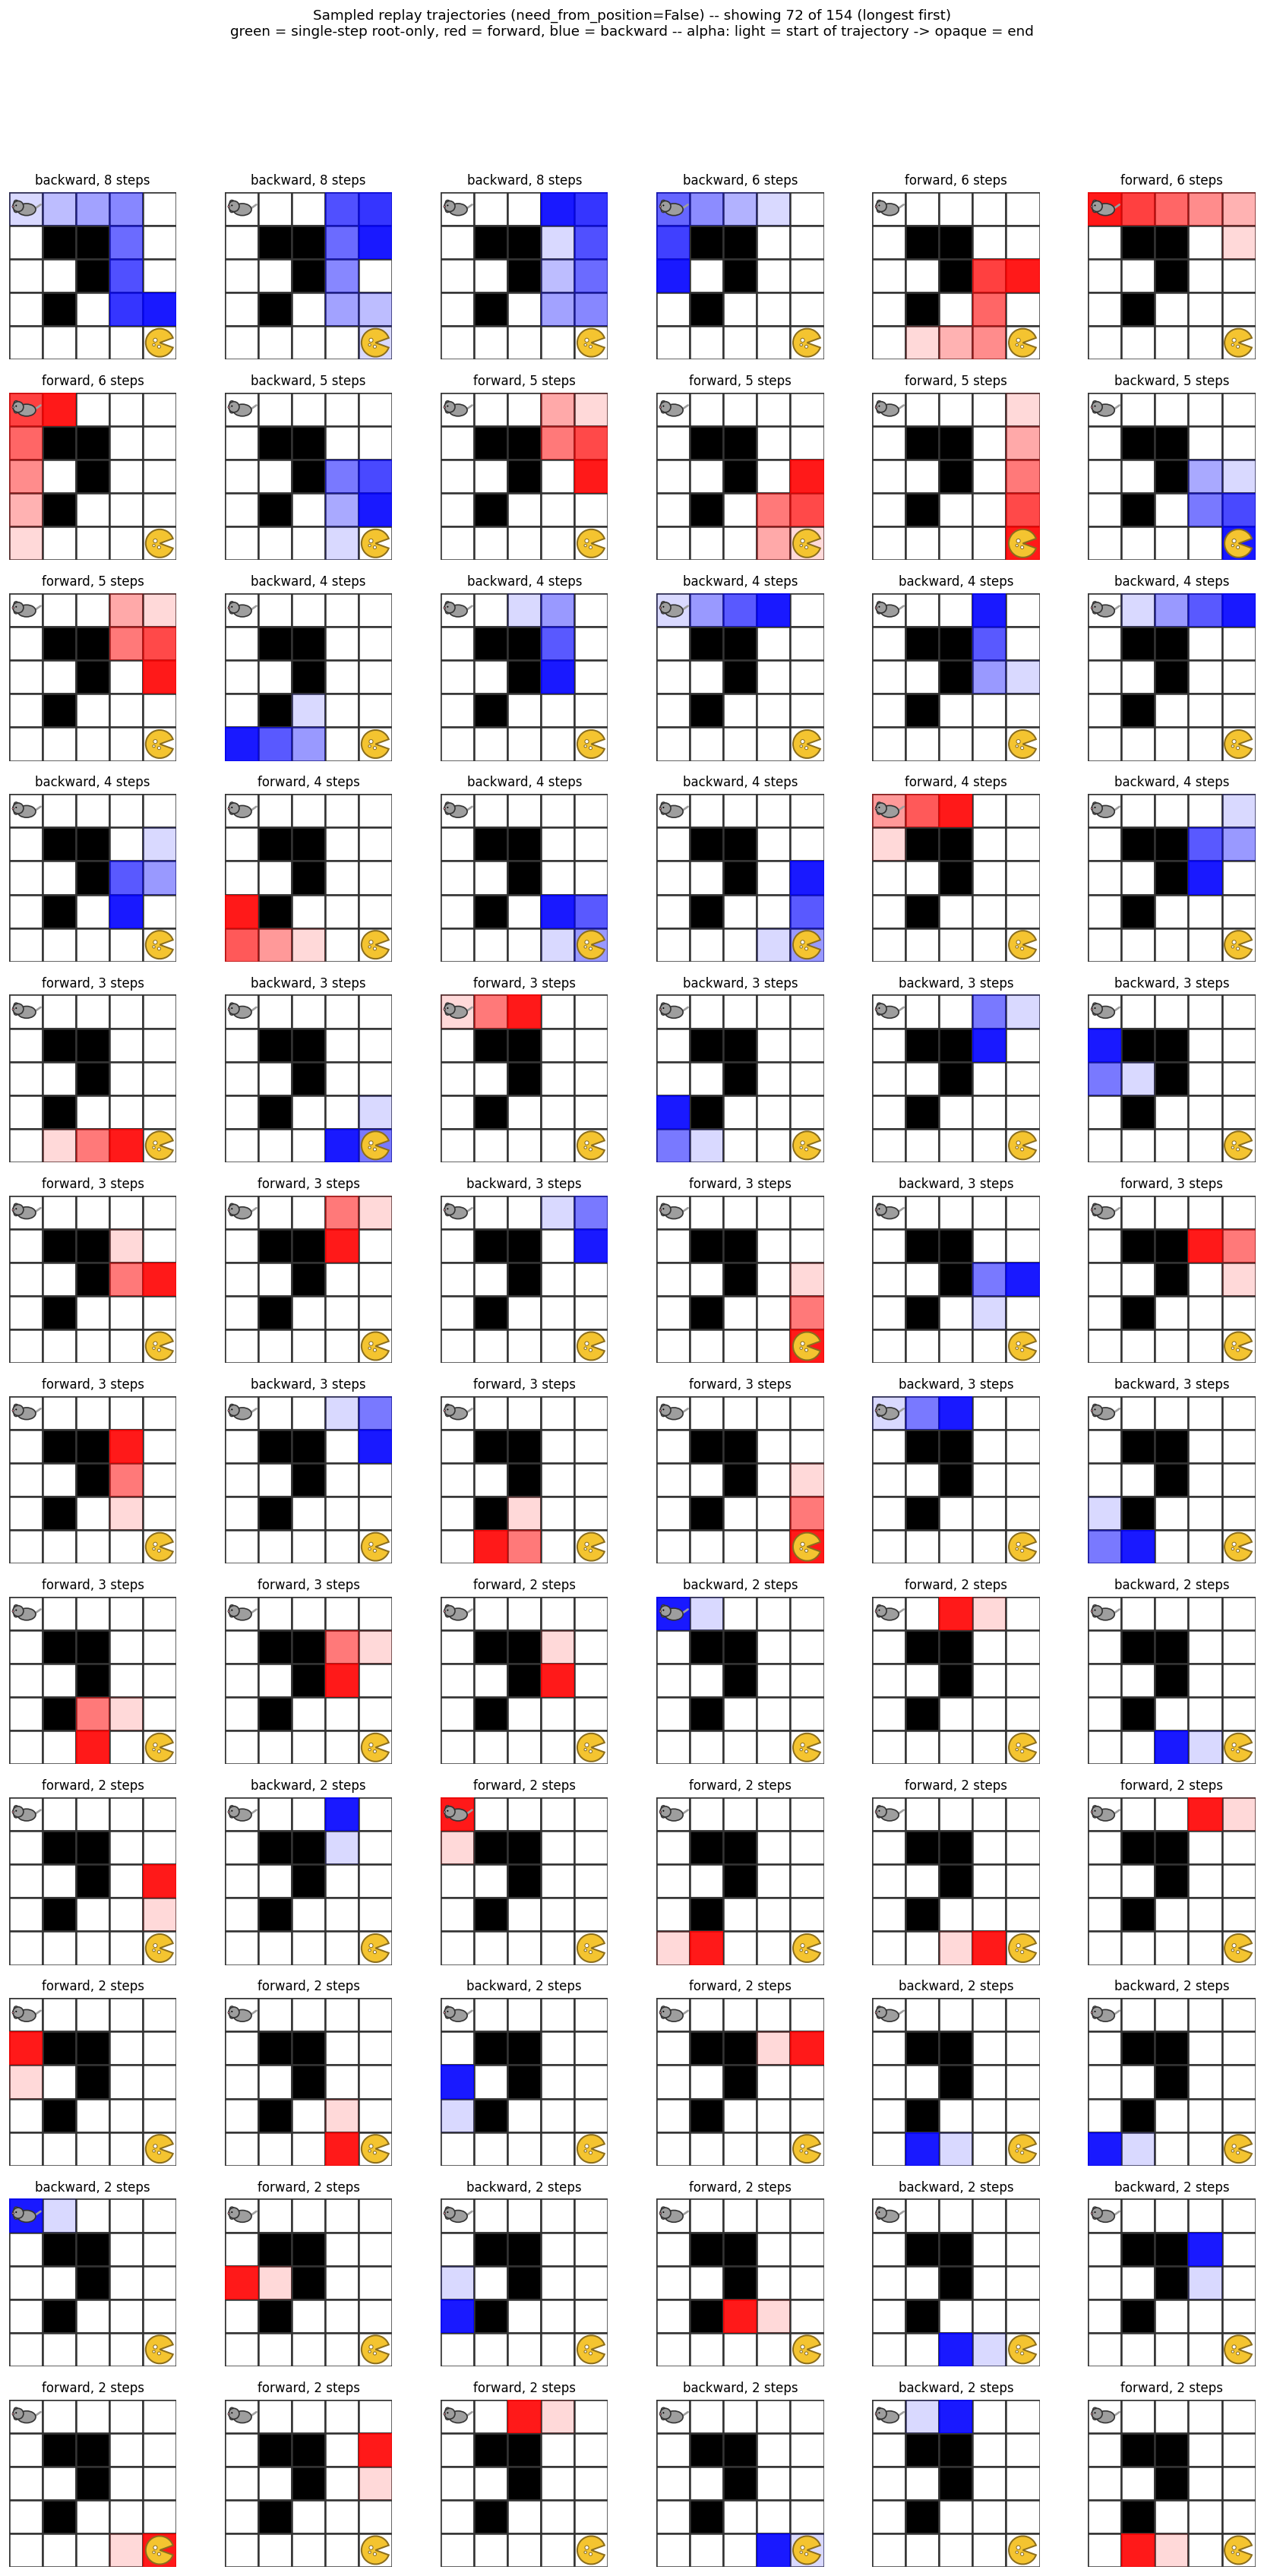

In [15]:
# --- Sample replay trajectories (need_from_position=False) -----------------
replay_agent.need_from_position = False
sequences, strategies, logs = replay_agent.sample_replay(temp=1.0, return_logs=True)
print(f"Sampled {len(sequences)} replay trajectories, lengths: {[len(t) for t in sequences]}")


def temporal_order(tree, strategy):
    """Return a tree's nodes in the order they were actually visited.

    Trees are stored in *append* order, which matches chronological order
    for forward and root-only trees but is exactly reversed for backward
    ones (each predecessor found is appended to the end). Forward and
    backward never mix within one tree -- switching direction requires a
    root reset, which starts a new tree -- so a single "backward" anywhere
    in `strategy` is enough to know the whole tree needs reversing.
    """
    if "backward" in strategy:
        return list(reversed(tree))
    return list(tree)


def plot_replay_tree(env, tree, strategy, ax):
    """Maze with this trajectory's visited states shaded green (single-step
    root-only), red (forward), or blue (backward), alpha increasing from
    the trajectory's true start (light) to its true end (opaque) -- using
    `strategy` to recover chronological order first.
    """
    ax.set_facecolor("white")
    env.maze_render(ax=ax)
    ordered = temporal_order(tree, strategy)
    n = len(ordered)
    direction = "backward" if "backward" in strategy else ("forward" if "forward" in strategy else "root only")
    color = "green" if direction == "root only" else ("blue" if direction == "backward" else "red")
    for i, sa in enumerate(ordered):
        r, c = env._decode(sa.state)
        alpha = 1.0 if n == 1 else 0.15 + 0.75 * (i / (n - 1))
        ax.add_patch(plt.Rectangle(
            (c - 0.5, -r - 0.5), 1, 1,
            facecolor=color, alpha=alpha, edgecolor="none", zorder=2,
        ))
    ax.set_title(f"{direction}, {n} step{'s' if n != 1 else ''}", fontsize=10, color="black")
    return ax


# Most bouts flush back to "root" quickly, so a run produces many short
# trees. Cap how many get plotted, longest first -- length-1 trees are the
# least informative and would otherwise fill a very tall, hard-to-scan grid.
MAX_TREES_TO_PLOT = 72
order = sorted(range(len(sequences)), key=lambda i: -len(sequences[i]))[:MAX_TREES_TO_PLOT]

n_trees = len(order)
ncols = min(n_trees, 6)
nrows = -(-n_trees // ncols)  # ceil
# Explicit white facecolor + black text everywhere, so the figure stays
# legible under a dark-mode Jupyter/IDE theme (which would otherwise render
# titles invisible, making it look like nothing was generated).
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 2.4, nrows * 2.4), facecolor="white")
axes = np.atleast_1d(axes).ravel()

for ax, i in zip(axes, order):
    plot_replay_tree(env, sequences[i], strategies[i], ax)
for ax in axes[n_trees:]:
    ax.axis("off")

fig.suptitle(
    f"Sampled replay trajectories (need_from_position=False) -- "
    f"showing {n_trees} of {len(sequences)} (longest first)\n"
    "green = single-step root-only, red = forward, blue = backward -- alpha: light = start of trajectory -> opaque = end",
    fontsize=11, color="black",
)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

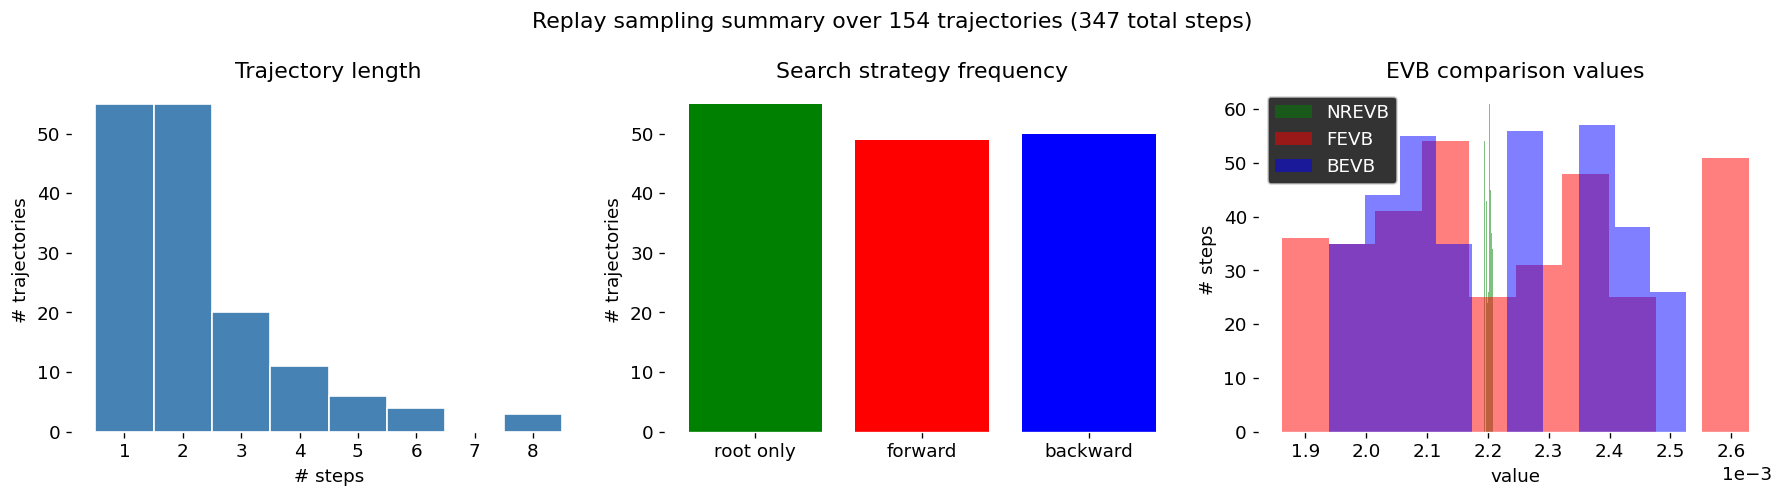

In [16]:
# --- Summary statistics across all sampled trajectories --------------------
# Trajectory lengths, strategy frequency (a tree's overall direction, not
# per-node), and the per-step NREVB/FEVB/BEVB values. NaNs in the logs mark
# each tree's first node, where no comparison was made yet, so drop them.
DIRECTION_ORDER = ["root only", "forward", "backward"]
DIRECTION_COLORS = ["green", "red", "blue"]


def tree_direction(strategy):
    """A tree's overall direction, from the per-node strategy labels."""
    if "backward" in strategy:
        return "backward"
    return "forward" if "forward" in strategy else "root only"


def plot_replay_summary(sequences, strategies, logs, suptitle=None):
    """Trajectory lengths, strategy frequency, and EVB comparison values."""
    trajectory_lengths = [len(t) for t in sequences]
    directions = [tree_direction(s) for s in strategies]
    direction_counts = [directions.count(d) for d in DIRECTION_ORDER]

    nrevb, fevb, bevb = (np.array(logs[k], dtype=float) for k in ("NREVB", "FEVB", "BEVB"))
    nrevb, fevb, bevb = nrevb[~np.isnan(nrevb)], fevb[~np.isnan(fevb)], bevb[~np.isnan(bevb)]

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), facecolor="white")
    for ax in axes:
        ax.set_facecolor("white")

    axes[0].hist(trajectory_lengths, bins=np.arange(1, max(trajectory_lengths) + 2) - 0.5,
                 color="steelblue", edgecolor="white")
    axes[0].set_title("Trajectory length", color="black")
    axes[0].set_xlabel("# steps")
    axes[0].set_ylabel("# trajectories")

    axes[1].bar(DIRECTION_ORDER, direction_counts, color=DIRECTION_COLORS)
    axes[1].set_title("Search strategy frequency", color="black")
    axes[1].set_ylabel("# trajectories")

    axes[2].hist(nrevb, bins=10, alpha=0.5, label="NREVB", color="green")
    axes[2].hist(fevb, bins=10, alpha=0.5, label="FEVB", color="red")
    axes[2].hist(bevb, bins=10, alpha=0.5, label="BEVB", color="blue")
    axes[2].set_title("EVB comparison values", color="black")
    axes[2].set_xlabel("value")
    axes[2].set_ylabel("# steps")
    axes[2].legend()
    # EVB magnitudes are small, so plain decimal ticks come out long and
    # collide at this width. Scientific notation with a shared exponent keeps
    # each tick label short.
    axes[2].ticklabel_format(style="sci", axis="x", scilimits=(0, 0))
    axes[2].xaxis.get_offset_text().set_color("black")

    for ax in axes:
        ax.title.set_color("black")
        ax.xaxis.label.set_color("black")
        ax.yaxis.label.set_color("black")
        ax.tick_params(colors="black")

    if suptitle is None:
        suptitle = (f"Replay sampling summary over {len(sequences)} trajectories "
                    f"({sum(trajectory_lengths)} total steps)")
    fig.suptitle(suptitle, color="black")
    plt.tight_layout()
    plt.show()


plot_replay_summary(sequences, strategies, logs)

## Experiment: one rewarded state

Everything above starts from a completely flat `q_model`, so replay has no
reason to prefer any part of the maze. Here we deliver a reward observation
to the goal cell, then re-run the sampler and look at where replay goes.

rewarded state: 24 (4, 4) (goal), all 4 actions
  before: mu=0.0000 var=0.02100  VPI=0.055010
  after : mu=3.0000 var=0.01050  VPI=0.038898
  V(goal) = 3.0000   V(elsewhere) = 0.0000


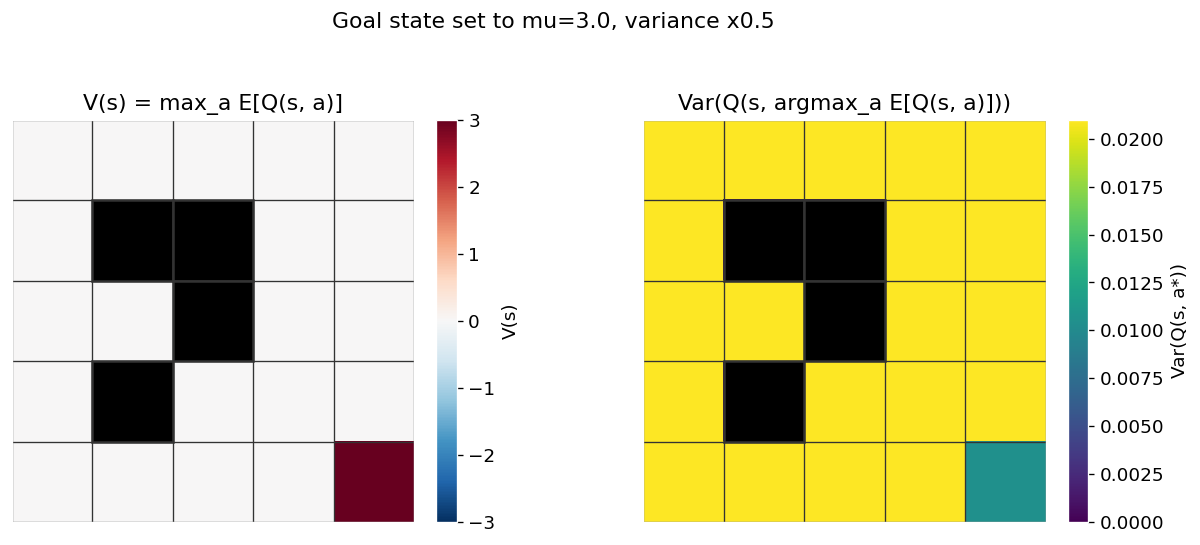

In [17]:
# --- 1. Reward the goal state directly --------------------------------------
# Reward convention: the agent collects the reward on *leaving* the rewarded
# cell, so every action out of the goal carries it. Q(s, a) is indexed by the
# state you depart from, so this is what puts the value on the cheese cell
# itself -- crediting the transitions that *enter* the goal would instead
# light up its neighbours, one step short of the cheese.
#
# Set directly rather than via q_model.update(): the mean is replaced
# outright with REWARD_MU and the variance halved (variance = beta /
# ((alpha - 1) * lam), so halving beta halves it), leaving lam/alpha alone.
REWARD_MU = 3.0
VARIANCE_SCALE = 0.5

goal_state = env.goal_encoded_states[0]
before = q_model.q_params(goal_state, 0)
vpi_before = q_model.vpi(goal_state, 0)

for a in range(env.n_actions):
    ng = q_model.q_params(goal_state, a)
    q_model._q[goal_state][a] = NormalGamma(
        mu=REWARD_MU, lam=ng.lam, alpha=ng.alpha, beta=ng.beta * VARIANCE_SCALE,
    )

after = q_model.q_params(goal_state, 0)
print(f"rewarded state: {goal_state} {env._decode(goal_state)} (goal), all {env.n_actions} actions")
print(f"  before: mu={before.mu:.4f} var={before.variance:.5f}  VPI={vpi_before:.6f}")
print(f"  after : mu={after.mu:.4f} var={after.variance:.5f}  VPI={q_model.vpi(goal_state, 0):.6f}")
print(f"  V(goal) = {q_model.value(goal_state):.4f}   V(elsewhere) = {q_model.value(start_state):.4f}")

# NOTE: EVB = VPI x Need, and VPI is the value of *perfect information* --
# how much learning the true Q would change the policy. With all four
# actions moved to the same mu, nothing distinguishes them, so VPI is
# completely independent of REWARD_MU (verify by re-running with 3.0 vs
# 0.0: VPI is identical). Halving the variance then *lowers* VPI, because a
# tighter posterior has less left to learn. So this makes the goal a weaker
# replay target, not a stronger one -- the opposite of raising its
# uncertainty. Kept as specified; see the printout above for the size.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), facecolor="white")
replay_agent.plot_value_function(env.height, env.width, walls=env.walls, ax=axes[0])
replay_agent.plot_value_variance(env.height, env.width, walls=env.walls, ax=axes[1])
fig.suptitle(f"Goal state set to mu={REWARD_MU}, variance x{VARIANCE_SCALE}", color="black")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

In [18]:
# --- 2. Sample 500 replay steps from the updated model ---------------------
# need_from_position=True anchors Need at the agent's real position (the
# start cell), so replay is pulled both by the agent's own location and by
# the reward-induced uncertainty at the far corner.
replay_agent.need_from_position = True
replay_agent.agent_real_state = start_state

sequences, strategies, logs = replay_agent.sample_replay(H=500, temp=1.0, return_logs=True)
print(f"Sampled {len(sequences)} trajectories from {sum(len(t) for t in sequences)} replay steps")

Sampled 156 trajectories from 345 replay steps


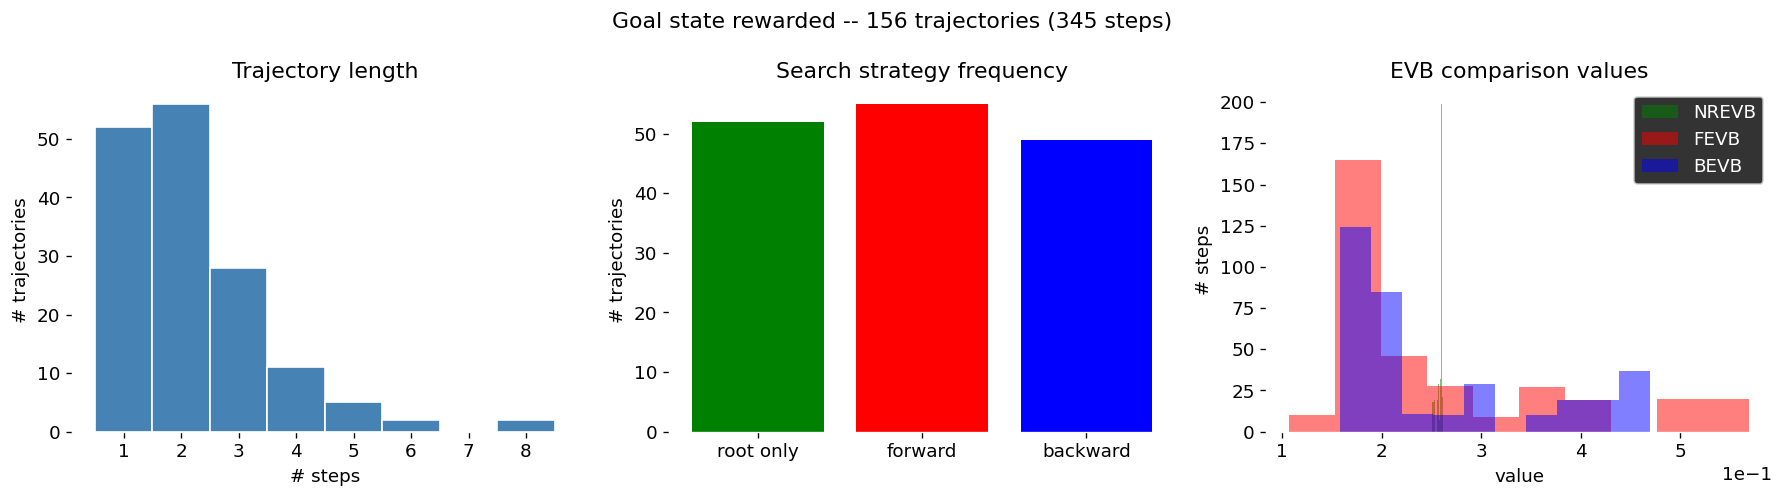

In [19]:
# --- 3. Same summary statistics as before ----------------------------------
plot_replay_summary(sequences, strategies, logs,
                    suptitle=f"Goal state rewarded -- {len(sequences)} trajectories "
                             f"({sum(len(t) for t in sequences)} steps)")

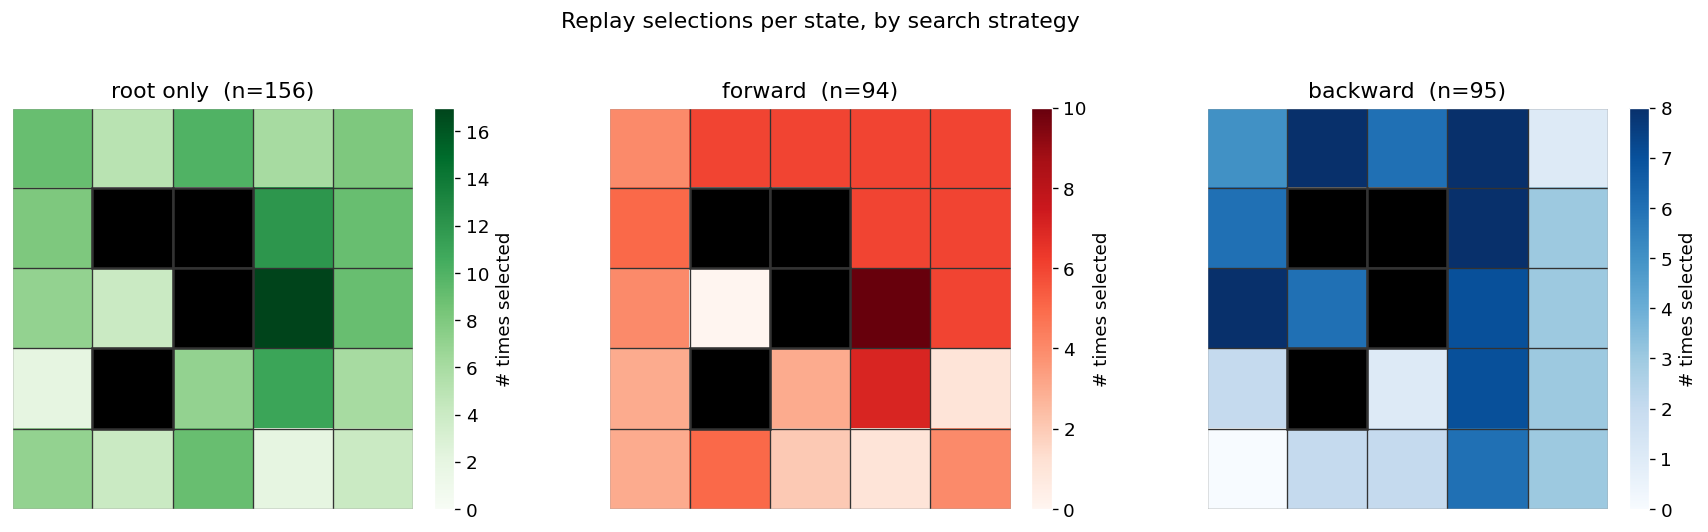

root only  total= 156  busiest states: (2, 3)=17, (1, 3)=12, (3, 3)=11
forward    total=  94  busiest states: (2, 3)=10, (3, 3)=7, (0, 1)=6
backward   total=  95  busiest states: (0, 1)=8, (0, 3)=8, (1, 3)=8


In [20]:
# --- 4. Where was each state selected, split by strategy --------------------
# strategies[i][j] is the strategy that *produced* node j of tree i: index 0
# is always the freshly sampled root, and every later node came from a
# forward or backward expansion. So counting nodes by their own label gives
# exactly "how often was this state picked as a new root / for forward
# replay / for backward replay".
counts = {name: np.zeros(env.n_states) for name in DIRECTION_ORDER}
name_of = {"root": "root only", "forward": "forward", "backward": "backward"}
for tree, strategy in zip(sequences, strategies):
    for node, node_strategy in zip(tree, strategy):
        counts[name_of[node_strategy]][node.state] += 1

# Each panel keeps its own colour scale -- root counts dominate, and a shared
# scale would wash the other two out. The totals in the titles are what make
# the panels comparable; the hues match the strategy colours used above.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), facecolor="white")
for ax, name, cmap in zip(axes, DIRECTION_ORDER, ["Greens", "Reds", "Blues"]):
    plot_state_grid(
        counts[name], env.height, env.width,
        title=f"{name}  (n={int(counts[name].sum())})",
        cbar_label="# times selected",
        walls=env.walls, ax=ax, cmap=cmap,
    )
fig.suptitle("Replay selections per state, by search strategy", color="black")
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

for name in DIRECTION_ORDER:
    c = counts[name]
    top = np.argsort(-c)[:3]
    print(f"{name:10s} total={int(c.sum()):4d}  busiest states: "
          + ", ".join(f"{tuple(int(x) for x in env._decode(s))}={int(c[s])}"
                       for s in top if c[s] > 0))